# Swiggy Restaurants: Exploratory Data Analysis
**Dataset:** Swiggy restaurant listings from Kaggle (~140k restaurants across India, 10 columns).
**Goal:** Clean the data and find patterns in cities, cuisines, pricing and ratings.
**Tools:** Python, Pandas, Matplotlib, Seaborn

In [25]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("swiggy_file.csv")
print(df.shape)
print(df.head())
df.info()
print(df.isnull().sum())
print(df.duplicated().sum())

(140657, 10)
   Restaurant Name               Cuisine Rating Number of Ratings  \
0  La Pino'Z Pizza        Pizzas, Pastas    4.0       10+ ratings   
1  The Second Wife  Indian, North Indian    3.6       50+ ratings   
2      Tasty Bites    Italian, Beverages    3.8       10+ ratings   
3      Food Studio       Pizzas, Burgers    3.5         8 ratings   
4     Roll Express     Fast Food, Snacks    4.3      100+ ratings   

  Average Price  Number of Offers  \
0  ₹250 for two                 2   
1  ₹250 for two                 2   
2  ₹200 for two                 1   
3   ₹49 for two                 5   
4  ₹200 for two                 2   

                                          Offer Name                    Area  \
0  FLAT DEAL\nFLAT ₹125 OFF\nUSE FLAT125ABOVE ₹69...  LALA LAJPAT RAI MARKET   
1  30% OFF UPTO ₹75\nUSE TRYNEWABOVE ₹149, FLAT ₹...          Central Abohar   
2               FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500          Central Abohar   
3  50% OFF UPTO ₹100\nUSE TRY

## Data Cleaning
- Removed 1,336 duplicate rows
- Converted `Rating` from text to numbers ("NEW" and "--" became missing values)
- Converted `Number of Ratings` (e.g. "5K+ ratings") and `Average Price` (e.g. "₹250 for two") to numeric columns
- Filled missing `Cuisine`, `Area` and `Offer Name` values; left missing ratings as NaN because they belong to new or unrated restaurants

In [26]:
df = df.drop_duplicates().reset_index(drop=True)

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

def parse_ratings(x):
    if pd.isna(x): return np.nan
    x = str(x).lower().replace("ratings", "").replace("+", "").strip()
    try:
        return float(x[:-1]) * 1000 if x.endswith("k") else float(x)
    except ValueError:
        return np.nan   # "too few"

df["Num_Ratings"] = df["Number of Ratings"].apply(parse_ratings)

df["Price"] = pd.to_numeric(df["Average Price"].str.extract(r"(\d+)")[0], errors="coerce")

df["Cuisine"] = df["Cuisine"].fillna("Unknown")
df["Area"] = df["Area"].fillna("Unknown")
df["Offer Name"] = df["Offer Name"].fillna("No offer")

df = df.rename(columns={"Location": "City", "Pure Veg": "Pure_Veg", "Number of Offers": "Num_Offers"})

print(df.shape)
print(df[["Rating", "Num_Ratings", "Price"]].describe())
print(df.isnull().sum())

(139321, 12)
              Rating    Num_Ratings          Price
count  105864.000000  105864.000000  139321.000000
mean        4.038306     547.969281     270.342554
std         0.495581    1627.172608     552.859926
min         1.000000       2.000000       1.000000
25%         3.800000      10.000000     200.000000
50%         4.100000      50.000000     250.000000
75%         4.300000     500.000000     300.000000
max         5.000000   10000.000000  199246.000000
Restaurant Name          0
Cuisine                  0
Rating               33457
Number of Ratings    14436
Average Price            0
Num_Offers               0
Offer Name               0
Area                     0
Pure_Veg                 0
City                     0
Num_Ratings          33457
Price                    0
dtype: int64


In [27]:
df["Price"].describe()

count    139321.000000
mean        270.342554
std         552.859926
min           1.000000
25%         200.000000
50%         250.000000
75%         300.000000
max      199246.000000
Name: Price, dtype: float64

<Axes: xlabel='Price'>

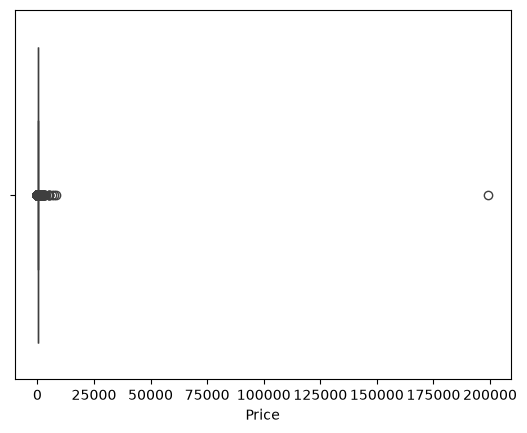

In [28]:
sns.boxplot(x=df["Price"])

## Outlier Handling
Some prices were clearly data entry errors, such as a restaurant listed at ₹1,99,246 for two and small stalls listed at ₹5,000+. I kept prices between ₹50 and ₹2,000, which removed 751 rows (138,570 rows remain).

0.010      80.0
0.950     500.0
0.990     800.0
0.999    1500.0
Name: Price, dtype: float64
                     Restaurant Name         City   Price
81455                  The Food Town     Lalitpur  199246
103838               Bluto'S Kitchen      Patiala    8000
2788         Jay Ashapura Restaurant    Ahmedabad    7490
132165      Shree Devi Baba Panipuri     Vadodara    6354
128474               Sai Snacks Spot       Trichy    5080
41827                  Ghar Ki Rasoi         Etah    5000
60516   Salasar Bakers And Fast Food       Jaipur    5000
75617                Pesto Restocafe     Kolhapur    5000
127115                  Majeeth Cafe  Tirunelveli    3500
127476               Club 10 Chicken     Tirupati    3250
727 restaurants under ₹50
751 rows removed


<Axes: xlabel='Price'>

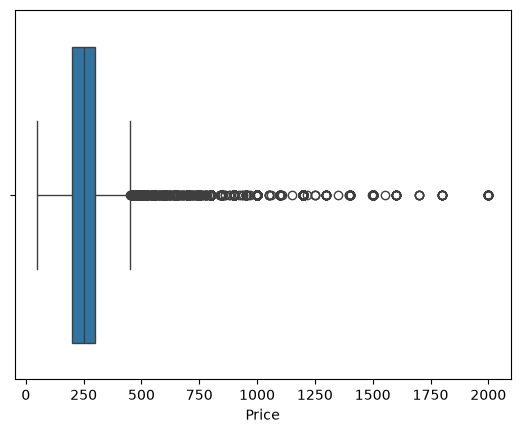

In [29]:
# Look at the extremes
print(df["Price"].quantile([0.01, 0.95, 0.99, 0.999]))
print(df.nlargest(10, "Price")[["Restaurant Name", "City", "Price"]])
print((df["Price"] < 50).sum(), "restaurants under ₹50")

# Keep realistic prices only
df_clean = df[(df["Price"] >= 50) & (df["Price"] <= 2000)].copy()
print(len(df) - len(df_clean), "rows removed")

# Re-plot
sns.boxplot(x=df_clean["Price"])

In [30]:
df_clean = df_clean.drop(columns=["Average Price", "Number of Ratings"])

In [31]:
df_clean

,Restaurant Name,Cuisine,Rating,Num_Offers,Offer Name,Area,Pure_Veg,City,Num_Ratings,Price
0,La Pino'Z Pizza,"Pizzas, Pastas",4.0,2,FLAT DEAL\nFLAT ₹125 OFF\nUSE FLAT125ABOVE ₹69...,LALA LAJPAT RAI MARKET,No,Abohar,10.0,250
1,The Second Wife,"Indian, North Indian",3.6,2,"30% OFF UPTO ₹75\nUSE TRYNEWABOVE ₹149, FLAT ₹...",Central Abohar,No,Abohar,50.0,250
2,Tasty Bites,"Italian, Beverages",3.8,1,FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500,Central Abohar,Yes,Abohar,10.0,200
4,Roll Express,"Fast Food, Snacks",4.3,2,DEAL OF DAY\n10% OFF UPTO ₹40\nUSE STEALDEALAB...,Circular Road,No,Abohar,100.0,200
5,Grill Masters,"Italian-American, Fast Food",4.1,1,FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500,Circular Road,No,Abohar,100.0,250
...,...,...,...,...,...,...,...,...,...,...
139316,Yummy Momo'S Cafe,"Chinese, Fast Food",4.6,3,"20% OFF UPTO ₹50\nUSE TRYNEWABOVE ₹149, FLAT ₹...",Yavatmal Locality,Yes,Yavatmal,3.0,100
139317,CAFE FIRST FLOOR,"Beverages, Snacks",3.2,2,"FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500, FLAT ₹50...",Yavatmal City,Yes,Yavatmal,3.0,200
139318,Cafe Coffee Aani Barach Kahi,Snacks,3.2,2,"FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500, FLAT ₹50...",Yavatmal Locality,Yes,Yavatmal,50.0,150
139319,Patil Family Restaurant,"North Indian, Biryani",4.3,2,"FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500, FLAT ₹50...",Yavatmal Locality,No,Yavatmal,9.0,200


## Q1: Which cities have the most restaurants?
**Insight:** Every top city has about 2,000 listings, which suggests the data was capped per city when it was collected. Because of this, city counts can't be compared, so I compare cities by average price instead.

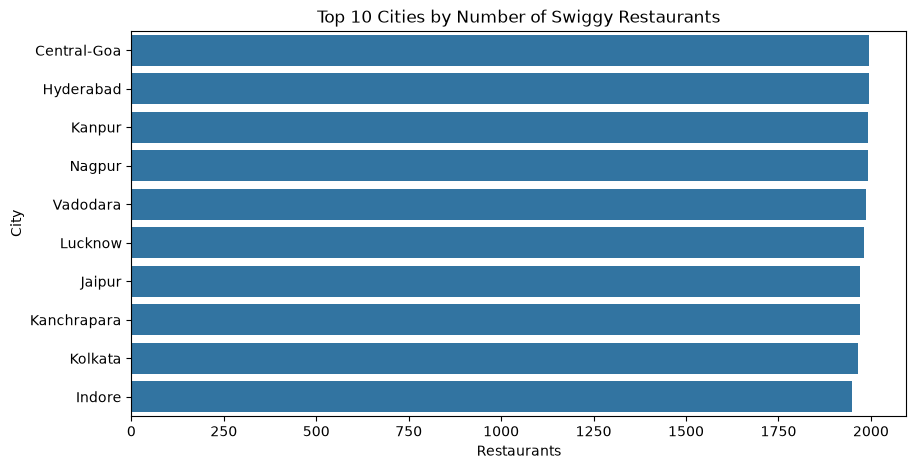

In [32]:
top_cities = df_clean["City"].value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_cities.values, y=top_cities.index)
plt.title("Top 10 Cities by Number of Swiggy Restaurants")
plt.xlabel("Restaurants")
plt.show()

## Q1: Which cities are the most expensive?
**Insight:** Central Goa is the priciest at about ₹480 for two, followed by Hyderabad at about ₹355. Most other cities sit around ₹250 to ₹280, and Kanpur and Lucknow are the cheapest.

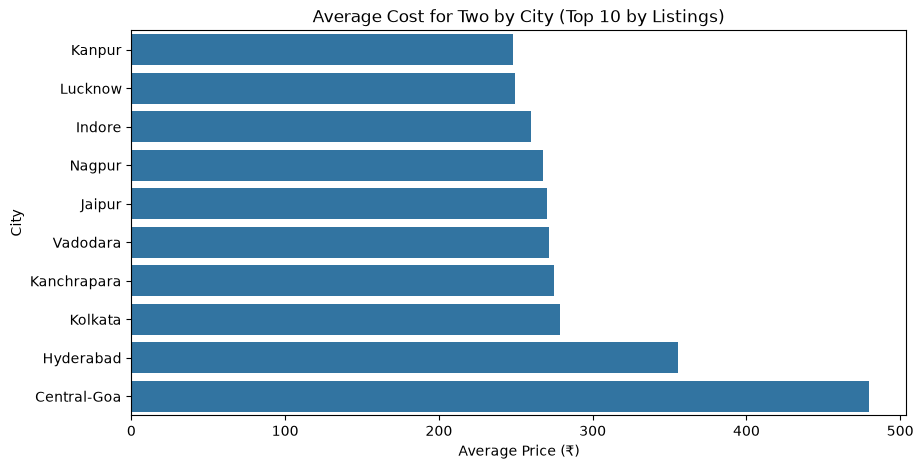

In [33]:
# Q1 : Average price in the 10 biggest cities
top10 = df_clean["City"].value_counts().head(10).index
city_price = df_clean[df_clean["City"].isin(top10)].groupby("City")["Price"].mean().sort_values()
plt.figure(figsize=(10,5))
sns.barplot(x=city_price.values, y=city_price.index)
plt.title("Average Cost for Two by City (Top 10 by Listings)")
plt.xlabel("Average Price (₹)")
plt.show()

## Q2: What are the most common cuisines?
**Insight:** Chinese is the most listed cuisine (about 37,000 mentions), ahead of North Indian (about 28,000) and Indian (about 23,000). Restaurants list multiple cuisines, so these are mentions rather than unique restaurants.

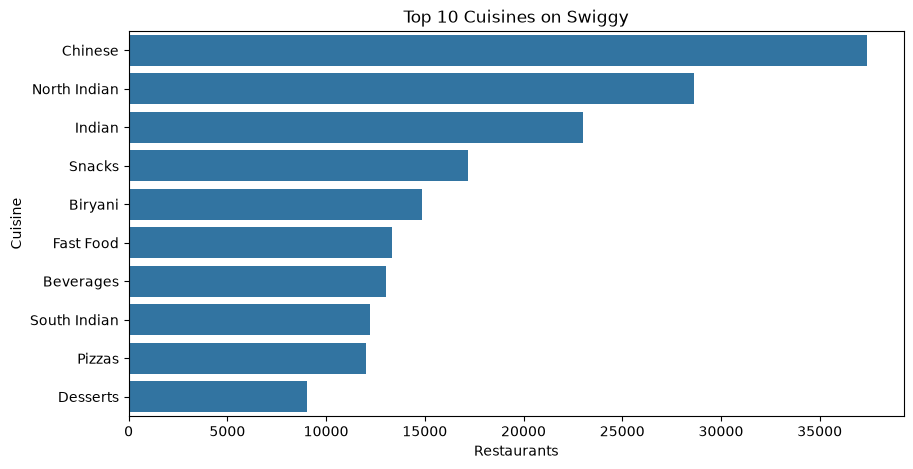

In [34]:
# Q2: Most common cuisines
cuisines = df_clean["Cuisine"].str.split(",").explode().str.strip()
cuisines = cuisines[cuisines != "Unknown"]
top_cuisines = cuisines.value_counts().head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index)
plt.title("Top 10 Cuisines on Swiggy")
plt.xlabel("Restaurants")
plt.show()

## Q3: Does a higher price mean a higher rating?
**Insight:** Not really. Average rating only rises from about 4.01 (₹150-250) to 4.13 (₹400+), and the median is about 4.1 in every price range. Paying more doesn't guarantee a better-rated restaurant.

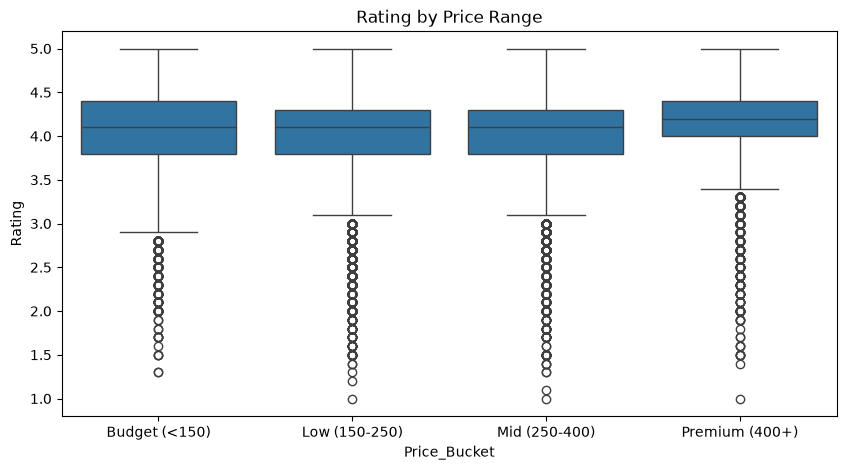

Price_Bucket
Budget (<150)     4.035419
Low (150-250)     4.012568
Mid (250-400)     4.054059
Premium (400+)    4.127901
Name: Rating, dtype: float64


In [35]:
# Q3: Does higher price mean higher rating?
df_clean["Price_Bucket"] = pd.cut(df_clean["Price"], bins=[0,150,250,400,2000],
                                  labels=["Budget (<150)", "Low (150-250)", "Mid (250-400)", "Premium (400+)"])
plt.figure(figsize=(10,5))
sns.boxplot(x="Price_Bucket", y="Rating", data=df_clean)
plt.title("Rating by Price Range")
plt.show()
print(df_clean.groupby("Price_Bucket", observed=True)["Rating"].mean())

## Q4: Do pure veg restaurants rate differently?
**Insight:** There's almost no difference. Pure veg restaurants average 4.06 and others average 4.03, so neither group is clearly better rated.

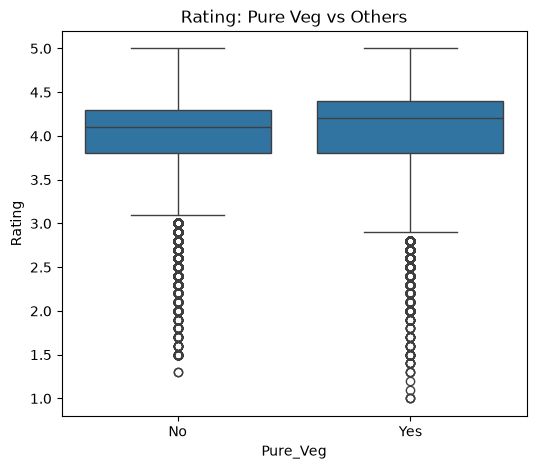

              mean  count
Pure_Veg                 
No        4.025693  62017
Yes       4.057365  43399


In [36]:
# Q4: Pure veg vs non-veg
plt.figure(figsize=(6,5))
sns.boxplot(x="Pure_Veg", y="Rating", data=df_clean)
plt.title("Rating: Pure Veg vs Others")
plt.show()
print(df_clean.groupby("Pure_Veg")["Rating"].agg(["mean", "count"]))